# 🚀 Aula 03 (Introdução Prática): Construindo uma Rede Simples com Divisão Treino e Teste

Neste notebook introdutório, vamos dar o próximo passo após a Aula 02 de forma bem simples e direta:
1. Dividir nossos dados reais em **Treino** e **Teste** (`train_test_split`).
2. Normalizar as variáveis **sem vazamento de dados (Data Leakage)**.
3. Organizar os dados com `Dataset` e `DataLoader` do PyTorch.
4. Construir e treinar uma **Rede Neural Simples (`nn.Module`)** para **Classificação** e **Regressão**, avaliando o desempenho real no conjunto de **Teste**!

---
## Parte 1: Classificação com Divisão Treino e Teste (E-commerce)

### 1. Carregando os Dados e Selecionando Atributos
Vamos carregar o dataset `E-commerce Customer Behavior - Sheet1.csv` e usar as variáveis numéricas dos clientes para prever seu nível de satisfação (`Unsatisfied`, `Neutral`, `Satisfied`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

torch.manual_seed(42)
np.random.seed(42)

# Carregar o CSV e remover linhas sem rótulo alvo
df = pd.read_csv("E-commerce Customer Behavior - Sheet1.csv").dropna(subset=["Satisfaction Level"])

# Selecionar as 5 colunas numéricas como entrada (X)
colunas_num = ["Age", "Total Spend", "Items Purchased", "Average Rating", "Days Since Last Purchase"]
X_bruto = df[colunas_num].values

# Transformar o alvo de texto (Neutral, Satisfied, Unsatisfied) em números (0, 1, 2)
le = LabelEncoder()
y_bruto = le.fit_transform(df["Satisfaction Level"].values)

print("Classes mapeadas:", dict(zip(le.classes_, range(len(le.classes_)))))
df[colunas_num + ["Satisfaction Level"]].head()

Classes mapeadas: {'Neutral': 0, 'Satisfied': 1, 'Unsatisfied': 2}


,Age,Total Spend,Items Purchased,Average Rating,Days Since Last Purchase,Satisfaction Level
0,29,1120.20,14,4.6,25,Satisfied
1,34,780.50,11,4.1,18,Neutral
2,43,510.75,9,3.4,42,Unsatisfied
3,30,1480.30,19,4.7,12,Satisfied
4,27,720.40,13,4.0,55,Unsatisfied


### 2. Divisão em Treino e Teste + Normalização sem *Data Leakage*

A **Regra de Ouro** do Machine Learning:
- Primeiro separamos os dados em **Treino (80%)** e **Teste (20%)**.
- Depois calculamos a média e o desvio padrão **apenas no Treino** (`.fit_transform()`) e aplicamos no Teste (`.transform()`).

In [2]:
# 1. Dividir em Treino (80%) e Teste (20%)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X_bruto, y_bruto, test_size=0.20, random_state=42, stratify=y_bruto
)

# 2. Normalizar SEM Data Leakage
scaler = StandardScaler()
X_treino = scaler.fit_transform(X_treino)  # Aprende média/desvio apenas no TREINO
X_teste = scaler.transform(X_teste)        # Usa a média/desvio do treino no TESTE

print(f"Amostras de Treino: {X_treino.shape[0]} | Amostras de Teste: {X_teste.shape[0]}")

Amostras de Treino: 278 | Amostras de Teste: 70


### 3. Criando o `Dataset` e o `DataLoader` no PyTorch

- A classe `Dataset` guarda nossos tensores e implementa 3 métodos simples: `__init__`, `__len__` e `__getitem__`.
- O `DataLoader` divide os dados em pequenos lotes (*mini-batches*) e embaralha os dados de treino (`shuffle=True`) a cada época.

In [3]:
class ClientesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)  # long (inteiro) para CrossEntropyLoss

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Criar Datasets e DataLoaders
treino_dataset = ClientesDataset(X_treino, y_treino)
teste_dataset = ClientesDataset(X_teste, y_teste)

treino_loader = DataLoader(treino_dataset, batch_size=32, shuffle=True)
teste_loader = DataLoader(teste_dataset, batch_size=32, shuffle=False)

# Inspecionar o primeiro lote (batch)
X_lote, y_lote = next(iter(treino_loader))
print(f"Formato do lote X: {X_lote.shape} | Formato do lote y: {y_lote.shape}")

Formato do lote X: torch.Size([32, 5]) | Formato do lote y: torch.Size([32])


### 4. Construindo a Rede Neural Simples (`nn.Module`)

Nossa rede recebe **5 atributos de entrada**, passa por uma camada oculta de **16 neurônios com ReLU** e entrega **3 saídas (Logits)** — uma para cada classe de satisfação.

> 💡 **Lembrete**: Como usaremos `nn.CrossEntropyLoss()`, não colocamos `Softmax` na última camada!

In [4]:
class RedeClassificacao(nn.Module):
    def __init__(self):
        super(RedeClassificacao, self).__init__()
        self.camada_oculta = nn.Linear(in_features=5, out_features=16)
        self.relu = nn.ReLU()
        self.camada_saida = nn.Linear(in_features=16, out_features=3)

    def forward(self, x):
        h = self.relu(self.camada_oculta(x))
        logits = self.camada_saida(h)
        return logits

modelo_clf = RedeClassificacao()
criterio_clf = nn.CrossEntropyLoss()
otimizador_clf = optim.Adam(modelo_clf.parameters(), lr=0.01)

print(modelo_clf)

RedeClassificacao(
  (camada_oculta): Linear(in_features=5, out_features=16, bias=True)
  (relu): ReLU()
  (camada_saida): Linear(in_features=16, out_features=3, bias=True)
)


### 5. Treinando a Rede e Avaliando no Conjunto de Teste

✅ Acurácia Final no Conjunto de Teste: 100.00%


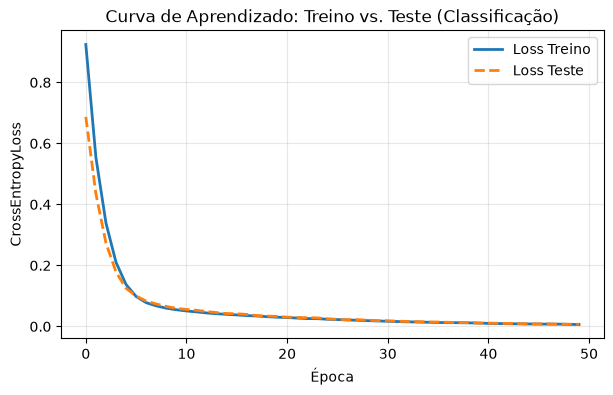

In [5]:
epocas = 50
historico_treino = []
historico_teste = []

for epoca in range(epocas):
    # --- TREINO ---
    modelo_clf.train()
    soma_erro_treino = 0.0
    for X_b, y_b in treino_loader:
        otimizador_clf.zero_grad()
        saida = modelo_clf(X_b)
        perda = criterio_clf(saida, y_b)
        perda.backward()
        otimizador_clf.step()
        soma_erro_treino += perda.item() * len(y_b)

    erro_medio_treino = soma_erro_treino / len(treino_dataset)
    historico_treino.append(erro_medio_treino)

    # --- AVALIAÇÃO NO TESTE ---
    modelo_clf.eval()
    soma_erro_teste = 0.0
    acertos = 0
    with torch.no_grad():
        for X_b, y_b in teste_loader:
            saida = modelo_clf(X_b)
            perda = criterio_clf(saida, y_b)
            soma_erro_teste += perda.item() * len(y_b)
            predicoes = saida.argmax(dim=1)
            acertos += (predicoes == y_b).sum().item()

    erro_medio_teste = soma_erro_teste / len(teste_dataset)
    historico_teste.append(erro_medio_teste)

acuracia_teste = (acertos / len(teste_dataset)) * 100
print(f"✅ Acurácia Final no Conjunto de Teste: {acuracia_teste:.2f}%")

plt.figure(figsize=(7, 4))
plt.plot(historico_treino, label="Loss Treino", linewidth=2)
plt.plot(historico_teste, label="Loss Teste", linewidth=2, linestyle="--")
plt.xlabel("Época")
plt.ylabel("CrossEntropyLoss")
plt.title("Curva de Aprendizado: Treino vs. Teste (Classificação)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---
## Parte 2: A Mesma Estrutura para Regressão (`insurance.csv`)

Veja como é simples adaptar exatamente o mesmo pipeline para um problema de **Regressão Contínua** (prever o valor do custo médico `charges` em dólares):
1. O alvo `y` passa a ser `torch.float32` com formato `(N, 1)`.
2. A camada de saída tem **1 neurônio** (`out_features=1`) sem função de ativação.
3. A função de perda passa a ser o Erro Quadrático Médio (`nn.MSELoss()`).

In [6]:
# 1. Carregar dados do Seguro Saúde e transformar variáveis simples
df_seguro = pd.read_csv("insurance.csv")
df_seguro["smoker_num"] = (df_seguro["smoker"] == "yes").astype(int)

X_seg = df_seguro[["age", "bmi", "children", "smoker_num"]].values
y_seg = df_seguro["charges"].values

# 2. Dividir em Treino (80%) e Teste (20%) e Normalizar sem Data Leakage
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(X_seg, y_seg, test_size=0.20, random_state=42)

scaler_seg = StandardScaler()
X_tr_s = scaler_seg.fit_transform(X_tr_s)
X_te_s = scaler_seg.transform(X_te_s)

# Converter para tensores
X_tr_tensor = torch.tensor(X_tr_s, dtype=torch.float32)
y_tr_tensor = torch.tensor(y_tr_s, dtype=torch.float32).unsqueeze(1)
X_te_tensor = torch.tensor(X_te_s, dtype=torch.float32)
y_te_tensor = torch.tensor(y_te_s, dtype=torch.float32).unsqueeze(1)

# 3. Rede Neural de Regressão (Saída = 1 neurônio contínuo)
class RedeRegressao(nn.Module):
    def __init__(self):
        super(RedeRegressao, self).__init__()
        self.camada_oculta = nn.Linear(4, 16)
        self.relu = nn.ReLU()
        self.camada_saida = nn.Linear(16, 1)

    def forward(self, x):
        return self.camada_saida(self.relu(self.camada_oculta(x)))

modelo_reg = RedeRegressao()
criterio_reg = nn.MSELoss()
otimizador_reg = optim.Adam(modelo_reg.parameters(), lr=0.1)

# 4. Loop de Treinamento
for epoca in range(300):
    otimizador_reg.zero_grad()
    pred = modelo_reg(X_tr_tensor)
    perda = criterio_reg(pred, y_tr_tensor)
    perda.backward()
    otimizador_reg.step()

# 5. Avaliar no Conjunto de Teste com MAE (Erro Médio Absoluto em Dólares)
with torch.no_grad():
    pred_teste = modelo_reg(X_te_tensor)
    mae_teste = torch.abs(pred_teste - y_te_tensor).mean().item()

print(f"✅ Erro Médio Absoluto (MAE) no Teste: US$ {mae_teste:,.2f}")
print("\nComparação das 5 primeiras previsões no Teste:")
for real, prev in zip(y_te_tensor[:5], pred_teste[:5]):
    print(f"   • Custo Real: US$ {real.item():9,.2f}  |  Previsto pela Rede: US$ {prev.item():9,.2f}")

✅ Erro Médio Absoluto (MAE) no Teste: US$ 4,088.99

Comparação das 5 primeiras previsões no Teste:
   • Custo Real: US$  9,095.07  |  Previsto pela Rede: US$  5,767.76
   • Custo Real: US$  5,272.18  |  Previsto pela Rede: US$  6,182.35
   • Custo Real: US$ 29,330.98  |  Previsto pela Rede: US$ 38,976.22
   • Custo Real: US$  9,301.89  |  Previsto pela Rede: US$  8,616.75
   • Custo Real: US$ 33,750.29  |  Previsto pela Rede: US$ 25,836.26
